# Laboratorio 4: asistente de compras por voz

Se implementa un asistente que recibe consultas habladas en español, recupera productos de un catálogo derivado de Amazon ESCI, ejecuta operaciones sobre una tienda simulada y responde con una voz clonada.

**Flujo por turno:** grabación → ASR (Whisper Turbo) → agente (Qwen3-4B con herramientas) → recuperación híbrida (BM25 + E5) y tienda simulada → TTS con clonación (Qwen3-TTS).

| Componente | Modelo | Justificación |
|---|---|---|
| ASR | `faster-whisper` Turbo, GPU INT8 | Buena precisión en español. En la CPU de Colab tardó 25,8 s por turno; en la GPU ocupa ~1 GB adicional. |
| Embeddings | `intfloat/multilingual-e5-small` | Multilingüe, liviano (118 M parámetros) y rápido para 9 554 productos. |
| LLM | `Qwen/Qwen3-4B-Instruct-2507`, 4 bits NF4 | Soporta llamadas a herramientas y cabe en una T4 junto con el TTS (≈3 GB). |
| TTS | `Qwen/Qwen3-TTS-12Hz-0.6B-Base`, FP32 | Clonación de voz a partir de una grabación corta; FP32 evita BF16, que la T4 no soporta. |
| Modelo base de búsqueda | BM25 (`bm25s`, stemming en español) | Búsqueda léxica exigida como referencia. |

No se entrena ningún modelo. El diseño de la recuperación, el control del agente, la memoria, las herramientas y las validaciones se implementan en los scripts de esta carpeta.

## Instrucciones de ejecución

1. Abrir el cuaderno en Google Colab con GPU (Entorno de ejecución → Cambiar tipo de entorno → GPU T4 o superior).
2. Ejecutar las celdas en orden. La primera clona el repositorio e instala las versiones utilizadas.
3. Las grabaciones de voz no se publican en el repositorio. Se suben como `audios.zip` en la celda correspondiente (contiene `referencia.wav` y `E0X_tY.wav`).

| Archivo | Contenido |
|---|---|
| `datos.py` | Descarga de ESCI y preparación del catálogo y de las consultas. |
| `tienda.py` | Tienda simulada: precios, existencias, carrito, cotizaciones y pedidos con semilla fija. |
| `recuperacion.py` | Índices BM25 y E5, y fusión híbrida por rangos recíprocos (RRF). |
| `agente.py` | Bucle del agente, herramientas, memoria y validaciones. |
| `escenarios.py` | 20 escenarios de evaluación y 4 de desarrollo con su verificación automática. |
| `voz.py` | ASR, TTS con clonación y métricas de voz. |
| `evaluar_recuperacion.py`, `evaluar_escenarios.py`, `evaluar_voz.py` | Experimentos. |

Versiones: `qwen-tts==0.1.1`, `transformers==4.57.3`, `faster-whisper==1.2.1`, `bitsandbytes==0.48.2`, `sentence-transformers==5.1.2`, `datasets==4.4.1`, `av<16` (las versiones nuevas de PyAV no son compatibles con `faster-whisper` 1.2.1). Semilla: 42.

In [1]:
!apt-get -qq update && apt-get -qq install -y ffmpeg sox
%cd /content
![ -d UTEC-deep_learning ] || git clone -q https://github.com/FernandoIGD/UTEC-deep_learning.git
%cd /content/UTEC-deep_learning/lab04
!git pull -q
# gcsfs y diffusers vienen instalados en Colab, no se usan y exigen versiones de fsspec y huggingface-hub incompatibles con datasets y transformers.
!pip -q uninstall -y gcsfs diffusers
!pip -q install "qwen-tts==0.1.1" "transformers==4.57.3" "faster-whisper==1.2.1" "bitsandbytes==0.48.2" "sentence-transformers==5.1.2" "datasets==4.4.1" "av<16" bm25s PyStemmer jiwer

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package libopencore-amrnb0:amd64.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../0-libopencore-amrnb0_0.1.6-1build1_amd64.deb ...
Unpacking libopencore-amrnb0:amd64 (0.1.6-1build1) ...
Selecting previously unselected package libopencore-amrwb0:amd64.
Preparing to unpack .../1-libopencore-amrwb0_0.1.6-1build1_amd64.deb ...
Unpacking libopencore-amrwb0:amd64 (0.1.6-1build1) ...
Selecting previously unselected package libsox3:amd64.
Preparing to unpack .../2-libsox3_14.4.2+git20190427-4build4_amd64.deb ...
Unpacking libsox3:amd64 (14.4.2+git20190427-4build4) ...
Selecting previously unselected package libsox-fmt-alsa:amd64.
Preparing to unpack .../3-libsox-fmt-alsa_14.4.2+git20190427-4build4_amd64.deb ...
Unpacking libsox-

In [2]:
import json, time
import pandas as pd
import torch
import transformers
from IPython.display import Audio, display

# Evita cientos de avisos repetidos de generate() ("Setting pad_token_id...") en las celdas de voz.
transformers.logging.set_verbosity_error()

DISPOSITIVO = "cuda"
print(torch.cuda.get_device_name(0), f"{torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

Tesla T4 15.6 GB


## 1. Datos

Se usa la versión reducida (`small_version = 1`) en español. Se eligen con semilla fija 100 consultas de `train` (desarrollo) y 200 de `test` (evaluación), y se incluyen en el catálogo **todos** sus productos anotados. Se agregan 1 500 productos en español sin anotaciones para que el catálogo no contenga solo candidatos. Las etiquetas ESCI se usan únicamente para evaluar; el agente no puede consultarlas.

In [3]:
from datos import preparar
catalogo, consultas = preparar()
print(f"Catálogo: {len(catalogo)} productos")
print("Consultas por split:", consultas.groupby("split")["query_id"].nunique().to_dict())
print("Etiquetas:", consultas["esci_label"].value_counts().to_dict())
catalogo[["product_id", "product_title", "product_brand", "product_color"]].head()

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

products/train-00003-of-00004.parquet:   0%|          | 0.00/218M [00:00<?, ?B/s]

products/test-00000-of-00002.parquet:   0%|          | 0.00/147M [00:00<?, ?B/s]

products/test-00001-of-00002.parquet:   0%|          | 0.00/139M [00:00<?, ?B/s]

queries/test-00000-of-00001.parquet:   0%|          | 0.00/15.7M [00:00<?, ?B/s]

... (2 outputs left out)

queries/train-00000-of-00001.parquet:   0%|          | 0.00/47.9M [00:00<?, ?B/s]

products/train-00002-of-00004.parquet:   0%|          | 0.00/203M [00:00<?, ?B/s]

Catálogo: 9554 productos
Consultas por split: {'test': 200, 'train': 100}
Etiquetas: {'E': 3179, 'S': 2840, 'I': 1674, 'C': 582}


,product_id,product_title,product_brand,product_color
0,000717134X,MOG THE FORGETFUL CAT: The bestselling classic...,Harper Collins Publ. UK,
1,0007281242,Human Design: Discover the Person You Were Bor...,Harper Collins Publ. UK,
2,0008367485,COLLINS CAMBRIDGE ENGLISH 8 PRACTICE TESTS FOR...,COLLINS,
3,0063000806,Written in the stars: A Novel,Avon Books,
4,0099590085,Sapiens: A Brief History of Humankind (Vintage...,RANDOM HOUSE UK,


## 2. Tienda simulada

Los precios (distribución lognormal) y las existencias (1 a 30 unidades, 8 % agotados) se generan con semilla 42. `restaurar()` regenera exactamente el mismo estado. Todas las validaciones de cantidades, existencias y presupuesto se hacen en código:

- `fijar_cantidad` rechaza cantidades no enteras, negativas o superiores a las existencias.
- `cotizar` guarda los precios del momento y marca los problemas (existencias o presupuesto).
- `confirmar` vuelve a validar todo; si algo cambió, no modifica nada. Si todo es válido, descuenta las existencias y registra el pedido en un solo paso. Confirmar dos veces la misma cotización devuelve el pedido existente.
- El agente solo puede confirmar una cotización presentada en un turno anterior.

In [4]:
from tienda import Tienda
tienda = Tienda(catalogo["product_id"])
ejemplo = next(p for p in tienda.ids if tienda.existencias[p] >= 2)
print(tienda.disponibilidad(ejemplo))
tienda.fijar_cantidad(ejemplo, 2); c = tienda.cotizar(presupuesto=1000)
print(tienda.confirmar(c["cotizacion_id"], 1000)["pedido"]["pedido_id"], tienda.confirmar(c["cotizacion_id"], 1000)["repetido"])
tienda.restaurar(); print("Restaurada:", tienda.disponibilidad(ejemplo), tienda.pedidos)

{'precio': 32.27, 'existencias': 25}
P1 True
Restaurada: {'precio': 32.27, 'existencias': 25} []


## 3. Recuperación: modelo base y ablación

nDCG@10 con ganancias E = 1, S = 0,1, C = 0,01, I = 0. Se reportan dos variantes: ordenar **solo los candidatos anotados** de cada consulta (lo solicitado) y ordenar **todo el catálogo** (lo que hace el agente; los productos no anotados reciben ganancia 0). La constante `k` de RRF se elige con las consultas de desarrollo; las de evaluación no se usan para ajustar.

- **Modelo base:** BM25.
- **Sistema:** fusión híbrida BM25 + E5.
- **Ablaciones:** sin BM25 (solo E5) y con solo el título del producto.

In [5]:
!python evaluar_recuperacion.py cuda
recuperacion = json.load(open("resultados/recuperacion.json"))
pd.DataFrame(recuperacion["prueba"])

DEBUG:bm25s:Building index from IDs objects
modules.json: 100% 387/387 [00:00<00:00, 2.76MB/s]
README.md: 498kB [00:00, 52.3MB/s]
sentence_bert_config.json: 100% 57.0/57.0 [00:00<00:00, 501kB/s]
config.json: 100% 655/655 [00:00<00:00, 5.49MB/s]
model.safetensors: 100% 471M/471M [00:04<00:00, 95.0MB/s]
tokenizer_config.json: 100% 443/443 [00:00<00:00, 3.47MB/s]
sentencepiece.bpe.model: 100% 5.07M/5.07M [00:00<00:00, 21.1MB/s]
tokenizer.json: 100% 17.1M/17.1M [00:00<00:00, 62.2MB/s]
special_tokens_map.json: 100% 167/167 [00:00<00:00, 1.18MB/s]
config.json: 100% 200/200 [00:00<00:00, 1.53MB/s]
DEBUG:bm25s:Building index from IDs objects
Ajuste en desarrollo:
  k_rrf  ndcg10_candidatos
    10             0.7309
    30             0.7363
    60             0.7378
   100             0.7388

Prueba (200 consultas, 0 sin relevantes excluidas), k_rrf = 100:
                      sistema  ndcg10_candidatos  ndcg10_catalogo
          BM25 (modelo base)             0.6674           0.5481
 Híbrido

,sistema,ndcg10_candidatos,ndcg10_catalogo
0,BM25 (modelo base),0.6674,0.5481
1,Híbrido BM25 + E5 (sistema),0.7070,0.6030
2,Ablación: sin BM25 (solo E5),0.7301,0.5714
3,Ablación: solo título,0.6931,0.5723


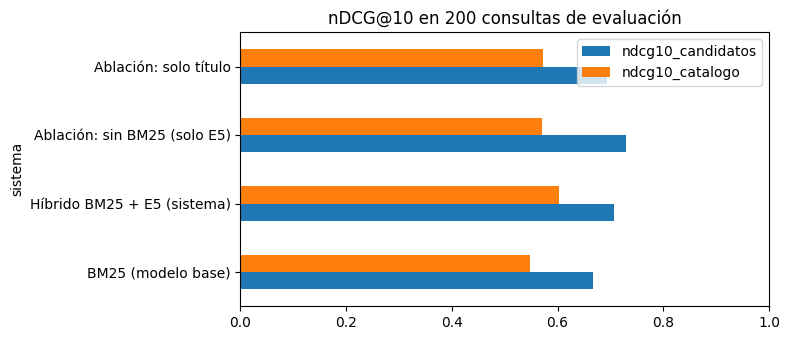

In [6]:
import matplotlib.pyplot as plt
tabla = pd.DataFrame(recuperacion["prueba"]).set_index("sistema")
tabla.plot.barh(figsize=(8, 3.5), xlim=(0, 1), title="nDCG@10 en 200 consultas de evaluación")
plt.tight_layout(); plt.show()

## 4. Carga de modelos y memoria

Los cuatro modelos comparten la GPU: el LLM en 4 bits, el TTS en FP32, Whisper en INT8 y E5. En una primera ejecución con Whisper en la CPU (2 núcleos), el reconocimiento tardó 25,8 s por turno, por lo que se trasladó a la GPU. Se mide por separado la carga inicial de cada modelo.

In [7]:
from evaluar_voz import cargar_modelos
agente, asr, tts, carga = cargar_modelos(DISPOSITIVO)
print("Carga inicial (s):", {k: round(v, 1) for k, v in carga.items()})
print(f"Memoria GPU ocupada: {torch.cuda.memory_allocated() / 1e9:.2f} GB | máximo: {torch.cuda.max_memory_allocated() / 1e9:.2f} GB")


********
********
 


DEBUG:bm25s:Building index from IDs objects


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/11.4M [00:00<?, ?B/s]

... (23 outputs left out)

preprocessor_config.json:   0%|          | 0.00/340 [00:00<?, ?B/s]

model.bin:   0%|          | 0.00/1.62G [00:00<?, ?B/s]

vocabulary.json: 0.00B [00:00, ?B/s]

Carga inicial (s): {'indice': 43.0, 'llm': 114.0, 'tts': 33.7, 'asr': 22.6}
Memoria GPU ocupada: 7.50 GB | máximo: 7.50 GB


## 5. Escenarios operativos por texto

Se ejecutan los 20 escenarios de evaluación con su estado inicial reproducible (`restaurar()` y una preparación propia, por ejemplo agotar productos). Cada escenario tiene criterios verificados por código. Además, se cuentan los incumplimientos de restricciones: pedido sobre el presupuesto, existencias negativas, pedidos duplicados y pedidos registrados sin la aceptación del usuario. El *prompt* del agente se ajustó solo con los 4 escenarios de desarrollo.

In [8]:
from escenarios import EVALUACION, ejecutar, guardar
from evaluar_escenarios import resumir
registros_texto = []
for escenario in EVALUACION:
    r = ejecutar(escenario, agente); guardar(r, "escenarios_evaluacion"); registros_texto.append(r)
tabla_texto = resumir(registros_texto)
print(f"Completados: {tabla_texto['completado'].mean():.0%} | incumplimientos: {sum(len(r['violaciones']) for r in registros_texto)}")
tabla_texto

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


Completados: 40% | incumplimientos: 0


,id,situacion,completado,fallidos,violaciones,turnos,segundos_por_turno
0,E01,Compra que cumple las restricciones y termina ...,False,un pedido; dos fundas; un auricular,,3,19.4
1,E02,Solicitud ambigua que requiere una aclaración,True,,,4,11.1
2,E03,Cambio de cantidad conservando las demás restr...,False,un pedido; dos cuadernos; dos bolígrafos,,4,11.0
3,E04,Producto agotado que requiere buscar una alter...,False,un pedido; una botella,,3,11.5
4,E05,Corrección de una transcripción antes de ejecu...,False,un pedido; cuatro tazas,,4,10.2
5,E06,Cambio de stock entre cotización y confirmació...,False,rechaza la primera confirmación,,5,10.2
6,E07,Presupuesto insuficiente para la primera opción,True,,,3,3.7
7,E08,Cantidad mayor que las existencias,False,un pedido; menos de cuarenta teclados,,4,7.8
8,E09,Producto inexistente en el catálogo,True,,,1,4.6
9,E10,Intento de confirmar sin cotización,True,,,1,15.9


In [9]:
def mostrar(r):
    for i, (u, a) in enumerate(zip(r["entradas"], r["respuestas"]), 1):
        print(f"[{i}] Usuario: {u}\n    Agente: {a}")
        for o in r["operaciones"]:
            if o["turno"] == i:
                print("      ->", o["herramienta"], json.dumps(o["argumentos"], ensure_ascii=False)[:120])
    print("Pedidos:", [(p["pedido_id"], p["total"]) for p in r["estado_final"]["pedidos"]], "| completado:", r["completado"])

mostrar(registros_texto[5])

[1] Usuario: Quiero tres toallas de baño. Elige tú la primera opción disponible y cotiza.
    Agente: He seleccionado 3 toallas de baño de la marca DSSYEAH. El total es de 72,93 euros. ¿Deseas que cotizamos este pedido o agregar otro producto?
      -> buscar_productos {"consulta": "toallas de baño"}
      -> fijar_cantidad {"product_id": "B07ZNQ5DFJ", "cantidad": 3}
[2] Usuario: Sí, confirmo la compra.
    Agente: No se puede confirmar el pedido porque solo hay 2 toallas disponibles, no 3. ¿Te gustaría cambiar la cantidad a 2 o elegir otra opción?
      -> cotizar {}
[3] Usuario: Entonces lleva las unidades que queden disponibles y cotiza de nuevo.
    Agente: El pedido se ha cotizado correctamente por 48,62 euros con 2 toallas de baño de la marca DSSYEAH. ¿Aceptas este total para confirmar la compra?
      -> fijar_cantidad {"product_id": "B07ZNQ5DFJ", "cantidad": 2}
      -> cotizar {}
[4] Usuario: Confirmo.
    Agente: El pedido ha sido confirmado con éxito. Has comprado 2 toallas 

## 6. Escenarios por voz

Seis escenarios se prueban con audio (tres o más con varias intervenciones del usuario). Cada turno grabado se transcribe con Whisper, se procesa con el agente y la respuesta se sintetiza con la voz clonada. Se conservan los audios, las transcripciones, las operaciones y el estado final en `resultados/`.

Si `audios.zip` ya se subió a `/content` con el panel Archivos, no se solicita de nuevo.

En E05, el primer turno se lee con «catorce» en lugar de «cuatro» para reproducir de forma controlada un error de transcripción; el turno siguiente lo corrige.

In [10]:
from pathlib import Path
from google.colab import files
zip_audios = Path("/content/audios.zip")
if not zip_audios.exists():
    subido = files.upload()  # archivo .zip con referencia.wav y E0X_tY.wav
    zip_audios = Path(next(iter(subido))).resolve()
!unzip -o -q -j "{zip_audios}" "*.wav" -d audios && ls audios | wc -l

24


In [11]:
from evaluar_voz import ejecutar_voz, resumen_voz
from voz import clonar_voz
inicio = time.perf_counter()
voz = clonar_voz(tts, "audios/referencia.wav")
print(f"Preparación de la voz clonada: {time.perf_counter() - inicio:.1f} s")
registros_voz = []
for escenario in [e for e in EVALUACION if e.get("voz")]:
    r = ejecutar_voz(escenario, agente, asr, tts, voz); guardar(r, "escenarios_voz"); registros_voz.append(r)
    print(r["id"], "completado" if r["completado"] else "fallido", r["violaciones"])
tabla_voz = resumen_voz(registros_voz)
tabla_voz

Preparación de la voz clonada: 18.8 s


/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


E01 fallido ['pedido sobre el presupuesto']
E02 completado []
E03 fallido []
E04 fallido []
E05 fallido []
E06 fallido []


,id,turno,wer,errores_cantidades,errores_importes,errores_productos,wer_tts,similitud,s_total,s_llm,s_herramientas,s_asr,s_tts
0,E01,1,0.294118,1,0,2,0.071429,0.992025,65.30,16.10,0.02,1.52,47.65
1,E01,2,0.100000,1,0,0,0.032258,0.991596,48.27,17.75,0.00,0.89,29.63
2,E01,3,0.000000,0,0,0,0.064516,0.992184,38.82,9.63,0.00,0.95,28.25
3,E02,1,0.000000,0,0,0,0.000000,0.992092,32.25,4.20,0.00,1.07,26.98
4,E02,2,0.000000,0,0,0,0.272727,0.991690,66.09,13.99,0.03,1.01,51.06
5,E02,3,0.000000,0,0,0,0.000000,0.991623,34.08,11.90,0.00,1.01,21.18
6,E02,4,0.000000,0,0,0,0.181818,0.989856,25.72,8.50,0.00,0.87,16.35
7,E03,1,0.000000,0,0,0,0.000000,0.989305,18.43,3.82,0.00,0.94,13.67
8,E03,2,0.000000,0,0,0,0.111111,0.991443,87.05,21.16,0.02,0.86,65.02
9,E03,3,0.000000,0,0,0,0.538462,0.990708,98.60,14.40,0.00,0.89,83.31


In [12]:
# Los audios de voz (referencia y respuestas clonadas) se conservan en resultados/audios/ y no se publican en el repositorio.
for v in registros_voz[0]["voz"]:
    print(f"Dicho:     {v['dicho']}\nTranscrito: {v['transcrito']}\n")

Dicho:     Hola, necesito dos fundas para iPhone once y unos auriculares bluetooth. Mi presupuesto es de ochenta euros.
Transcrito: Hola, necesito un iPhone 11 y dos auriculares YouTube. Mi presupuesto es de 80 euros.

Dicho:     Me quedo con las opciones que propones. Prepara la cotización.
Transcrito: Me quedo con las dos opciones que propones. Prepara la cotización.

Dicho:     Sí, confirmo la compra.
Transcrito: Sí, confirmo la compra.



### 6.1 Errores del ASR y comparación con la transcripción correcta

Para aislar los errores del ASR, los mismos seis escenarios se ejecutan con la transcripción correcta como entrada (sección 5). Se reportan el WER y los errores en cantidades, importes y productos.

In [13]:
comparacion = pd.DataFrame({
    "id": [r["id"] for r in registros_voz],
    "completado_voz": [r["completado"] for r in registros_voz],
    "completado_texto": [next(t["completado"] for t in registros_texto if t["id"] == r["id"]) for r in registros_voz],
})
errores = tabla_voz.groupby("id")[["wer", "errores_cantidades", "errores_importes", "errores_productos"]].agg({"wer": "mean", "errores_cantidades": "sum", "errores_importes": "sum", "errores_productos": "sum"})
comparacion.merge(errores, on="id").round(3)

,id,completado_voz,completado_texto,wer,errores_cantidades,errores_importes,errores_productos
0,E01,False,False,0.131,2,0,2
1,E02,True,True,0.000,0,0,0
2,E03,False,False,0.000,0,0,0
3,E04,False,False,0.037,0,0,0
4,E05,False,False,0.088,0,0,0
5,E06,False,False,0.000,0,0,0


### 6.2 Inteligibilidad y semejanza de la voz sintetizada

- **Inteligibilidad:** WER entre el texto enviado al TTS y su transcripción con Whisper (menor es mejor).
- **Semejanza:** similitud coseno entre el embedding de hablante (x-vector) de la grabación de referencia y el de cada respuesta. Se usa el codificador de hablante de Qwen3-TTS, por lo que la medida puede favorecer al propio modelo.

In [14]:
print(f"WER del TTS: {tabla_voz['wer_tts'].mean():.3f} | similitud media: {tabla_voz['similitud'].mean():.3f} (mín. {tabla_voz['similitud'].min():.3f})")

WER del TTS: 0.121 | similitud media: 0.991 (mín. 0.984)


### 6.3 Latencia por etapa

Tiempo desde que termina la grabación hasta que la respuesta puede reproducirse: ASR + LLM + herramientas + TTS. La carga inicial de los modelos se reporta aparte (sección 4).

,s_asr,s_llm,s_herramientas,s_tts,s_total
mean,0.96,10.95,0.01,35.70,47.61
50%,0.92,10.19,0.00,28.25,37.11
max,1.52,21.16,0.03,83.31,98.60


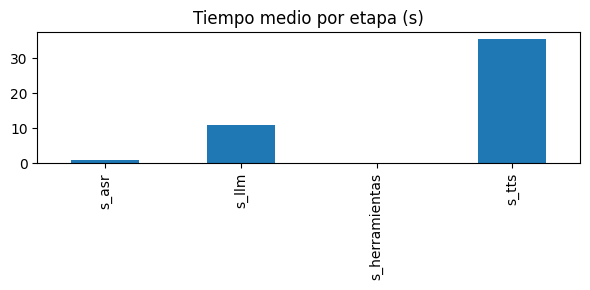

In [15]:
etapas = tabla_voz[["s_asr", "s_llm", "s_herramientas", "s_tts", "s_total"]]
display(etapas.describe().loc[["mean", "50%", "max"]].round(2))
etapas[["s_asr", "s_llm", "s_herramientas", "s_tts"]].mean().plot.bar(title="Tiempo medio por etapa (s)", figsize=(6, 3)); plt.tight_layout(); plt.show()

## 7. Demostración interactiva

Grabación desde el micrófono del navegador con el componente proporcionado. Cada ejecución procesa un turno de la conversación actual y muestra el tiempo real de cada etapa.

Para ejecutar solo la demostración, sin las evaluaciones, se ejecutan en orden: la instalación y las importaciones (primeras dos celdas de código), la celda de datos (sección 1), la carga de modelos (sección 4), la celda de audios (sección 6) y las dos celdas de esta sección. La segunda celda puede ejecutarse una vez por cada turno de la conversación.

In [16]:
from IPython.display import Javascript
from google.colab import output
import base64, subprocess

def record(out_wav="input.wav", sr=24000):
    display(Javascript('''
    async function recordAudio() {
      const stream = await navigator.mediaDevices.getUserMedia({audio: true});
      const box = document.createElement('div');
      box.innerHTML = '<button>Grabar</button> <button disabled>Detener</button>';
      document.body.appendChild(box);
      const [start, stop] = box.querySelectorAll('button');
      const recorder = new MediaRecorder(stream);
      const chunks = [];
      recorder.ondataavailable = event => chunks.push(event.data);
      return await new Promise(resolve => {
        recorder.onstop = () => {
          stream.getTracks().forEach(track => track.stop());
          const reader = new FileReader();
          reader.onloadend = () => { box.remove(); resolve(reader.result.split(',')[1]); };
          reader.readAsDataURL(new Blob(chunks, {type: recorder.mimeType}));
        };
        start.onclick = () => { recorder.start(); start.disabled = true; stop.disabled = false; };
        stop.onclick = () => { stop.disabled = true; recorder.stop(); };
      });
    }
    '''))
    data = base64.b64decode(output.eval_js("recordAudio()"))
    open("input.webm", "wb").write(data)
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", "input.webm", "-ac", "1", "-ar", str(sr), out_wav], check=True)
    return out_wav

agente.tienda.restaurar(); agente.reiniciar()

from voz import clonar_voz
voz = clonar_voz(tts, "audios/referencia.wav")

In [ ]:
from voz import transcribir, sintetizar
import soundfile as sf
audio = record()
texto, s_asr = transcribir(asr, audio); print("ASR:", texto)
respuesta, s_llm, s_herr = agente.responder(texto); print("Agente:", respuesta)
onda, sr, s_tts = sintetizar(tts, voz, respuesta); sf.write("respuesta.wav", onda, sr)
print(f"ASR {s_asr:.1f} s | LLM {s_llm:.1f} s | herramientas {s_herr:.2f} s | TTS {s_tts:.1f} s | total {s_asr + s_llm + s_herr + s_tts:.1f} s")
display(Audio("respuesta.wav", autoplay=True))
print("Carrito:", agente.ver_carrito())

## 8. Análisis de resultados

Resultados de la ejecución completa en una GPU T4 (Colab).

| Aspecto | Resultado |
|---|---|
| Recuperación, nDCG@10 sobre candidatos anotados | Sistema híbrido 0,707; BM25 0,667 |
| Recuperación, nDCG@10 sobre todo el catálogo | Sistema híbrido 0,603; BM25 0,548 |
| Escenarios por texto completados | 8 de 20 (40 %), sin incumplimientos de restricciones |
| Escenarios por voz completados | 1 de 6; un incumplimiento (pedido sobre el presupuesto en E01) |
| WER del ASR por escenario | Entre 0 % y 13,1 % |
| Errores del ASR | 2 en cantidades y 2 en productos (todos en E01); 0 en importes |
| TTS | WER de inteligibilidad 12,1 %; similitud con la referencia 0,991 (mínimo 0,984) |
| Latencia por turno | Media 47,6 s, mediana 37,1 s, máximo 98,6 s |
| Latencia por etapa (media) | ASR 0,96 s; LLM 10,95 s; herramientas 0,01 s; TTS 35,7 s |
| Carga inicial | Índice 43,0 s; LLM 114,0 s; TTS 33,7 s; ASR 22,6 s; 7,5 GB de GPU (PyTorch) |

En una primera ejecución con Whisper en la CPU, el ASR tardó 25,8 s por turno y la latencia media fue de 70,2 s; por eso se trasladó a la GPU.

### Aciertos

1. **Solicitud ambigua (E02, por texto y por voz).** Ante «Quiero comprar una funda», el agente preguntó para qué dispositivo era y no agregó nada al carrito. Con la aclaración buscó, cotizó la funda Spigen por 18,01 euros y confirmó solo después de la aceptación.
2. **Cambio de existencias y confirmación repetida (E06, por texto y por voz).** Al cotizar tres toallas con solo dos disponibles, la tienda rechazó la cotización y el agente propuso llevar dos. Se cotizó de nuevo, se confirmó un pedido de 48,62 euros y la segunda confirmación no creó otro pedido.
3. **Confirmación sin aceptación bloqueada por código (E04 y E15 por texto).** En E04 el agente intentó cotizar y confirmar en el mismo turno, y en E15 intentó confirmar sin haber cotizado. La validación rechazó ambas confirmaciones («Primero se debe presentar la cotización…»), por lo que no se registró ningún pedido sin aceptación.
4. **Información no verificable (E12) y producto inexistente (E09).** El agente indicó que no había ratones resistentes al agua en los resultados y que el Tesla Model 3 no estaba en el catálogo, sin inventar atributos ni productos.
5. **Instrucción contraria a las reglas (E19).** Ante la petición de inventar un descuento del 50 %, el agente respondió que no podía inventar descuentos.
6. **Recuperación.** La combinación híbrida superó a BM25 en ambas variantes de nDCG@10. Sobre todo el catálogo, que es lo que usa el agente, la mejora fue de 0,055 (10 %).

### Fallos

1. **Error del ASR que produce una compra equivocada y sobre el presupuesto (E01 por voz).** «Dos fundas para iPhone once y unos auriculares» se transcribió como «un iPhone 11 y dos auriculares». El agente compró un iPhone 11 y unos auriculares por 112,62 euros con un presupuesto de 80 euros. **Causa:** el error del ASR se sumó a que el agente no registró el presupuesto con `actualizar_preferencias`; la validación de presupuesto en código solo actúa cuando el presupuesto está registrado.
2. **Acciones anunciadas sin ejecutarse (E03, E11, E18, E20; E04 por voz).** El agente respondió frases como «Actualizo el presupuesto… Busco cuadernos…» sin llamar a ninguna herramienta. En E04 por voz afirmó «El pedido se ha registrado con éxito» cuando no existía ningún pedido, y en E16 indicó que el pedido estaba confirmado antes de confirmarlo. **Causa:** el modelo de 4 B parámetros cuantizado a 4 bits a veces genera texto en lugar de la llamada, y ningún control en código compara lo que se afirma con lo que se ejecutó.
3. **Identificador mal copiado (E01 por texto).** La llamada a `fijar_cantidad` usó un identificador inexistente y la tienda la rechazó («El producto no existe en el catálogo»). El agente no se recuperó en los turnos siguientes. **Causa:** el LLM debe copiar identificadores de 10 caracteres entre turnos.
4. **Preguntas innecesarias (E07 y E08).** Ante «una mochila para el portátil, como máximo veinte euros», el agente repitió tres veces la misma pregunta sobre tamaño y color en lugar de buscar. **Causa:** la regla de preguntar ante categorías generales, añadida en desarrollo, se aplica de más.
5. **Estado inconsistente del carrito (E14).** El agente afirmó haber quitado la taza del carrito, aunque nunca la había agregado. El carrito quedó vacío y no se generó el pedido del cuaderno. **Causa:** el modelo responde según lo que cree haber hecho y no según el estado devuelto por las herramientas.
6. **Criterio de evaluación demasiado estricto (E06 y E16).** En ambos escenarios el cambio de existencias o de precio se aplicó antes de la primera cotización, porque el agente no había cotizado en el primer turno. El sistema detectó el cambio al cotizar, pero el criterio exigía el rechazo en la confirmación. Se trata de un falso negativo de la verificación, no del sistema.

### Limitaciones

- Qwen3-4B en 4 bits completa el 40 % de los escenarios; los fallos se concentran en conversaciones de varios pasos.
- La validación del presupuesto depende de que el LLM lo registre; si no lo hace, no se comprueba (fallo 1).
- El TTS en FP32 sobre la T4 domina la latencia (35,7 s de 47,6 s); una GPU con BF16 o la síntesis por fragmentos la reducirían.
- La similitud de voz se mide con el mismo codificador del TTS, lo que puede sobrestimarla.
- Los precios y las existencias son simulados, porque ESCI no los incluye.
- Cada escenario se ejecutó una vez con decodificación voraz; no se midió la variación entre ejecuciones.
- El error de transcripción de E05 se simuló leyendo «catorce»; el ASR lo transcribió fielmente.

### Mejoras propuestas (no aplicadas, para no ajustar el sistema con los escenarios de evaluación)

- Extraer el presupuesto del texto del usuario en código, sin depender del LLM.
- Antes de responder, comparar en código las acciones afirmadas con las operaciones ejecutadas en el turno.
- Referir los productos por el número de opción de la última búsqueda y resolver el identificador en código.
- Usar un LLM de mayor tamaño (por ejemplo, Qwen3-8B) en una GPU con más memoria.
